# Day 09 — Statistics for Data Analytics
**Internship task | 23 November 2026**

**Objective:** Calculate 11 statistical concepts using a realistic, synthetic retail sales dataset and explain the meaning of each result. All financial amounts are INR. The dataset is generated for training, not actual business records.

## 1. Dataset and setup
The dataset has 40 orders, including quantity, unit price, discount, revenue and customer rating. Revenue = Quantity × UnitPrice × (1 − DiscountPct/100). We analyze **Revenue** and compare it with **Quantity**. The sample variance and standard deviation use `ddof=1`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.max_columns', 12)
df = pd.read_csv('Day09_Statistics_Dataset.csv', parse_dates=['OrderDate'])
print('Shape:', df.shape)
print(df.head(5).to_string(index=False))
print('Missing values:', int(df.isna().sum().sum()))

Shape: (40, 8)
OrderID  OrderDate    Category  Quantity  UnitPrice  DiscountPct  Revenue  CustomerRating
  S1001 2026-09-02    Clothing         3       1200            0   3600.0               3
  S1002 2026-09-03    Clothing        14        600           10   7560.0               3
  S1003 2026-09-04        Home        10        250           10   2250.0               4
  S1004 2026-09-05        Home        10        250           10   2250.0               2
  S1005 2026-09-06 Electronics         8        250            5   1900.0               5
Missing values: 0


## 2. Statistical calculations and interpretations
Each section states the formula or definition, calculates a result, and explains how to interpret it. Pandas uses linear interpolation by default for quantiles.

### 2.1 Mean
**Definition / formula:** Sum of observations divided by number of observations. Formula: x̄ = Σx / n.

**Business interpretation:** Typical revenue per order; affected by high-value orders.

In [2]:
result = df['Revenue'].mean()
print('Mean:', result)

Mean: 6679.0625


### 2.2 Median
**Definition / formula:** Middle ordered observation (or average of two middle observations).

**Business interpretation:** Central order revenue; less affected by extreme values.

In [3]:
result = df['Revenue'].median()
print('Median:', result)

Median: 4695.0


### 2.3 Mode
**Definition / formula:** Most frequent observation; multiple modes are possible.

**Business interpretation:** Most commonly repeated order revenue; may not be unique.

In [4]:
result = df['Revenue'].mode().tolist()
print('Mode:', result)

Mode: [2250.0, 5100.0, 7560.0, 7650.0, 20400.0]


### 2.4 Range
**Definition / formula:** Maximum − minimum.

**Business interpretation:** Spread between the smallest and largest order revenues.

In [5]:
result = df['Revenue'].max() - df['Revenue'].min()
print('Range:', result)

Range: 19725.0


### 2.5 Variance
**Definition / formula:** Sample variance: s² = Σ(x − x̄)² / (n − 1). Units: INR².

**Business interpretation:** Squared dispersion of revenue; not directly in rupees.

In [6]:
result = df['Revenue'].var(ddof=1)
print('Variance:', result)

Variance: 28258246.374198716


### 2.6 Standard deviation
**Definition / formula:** Sample SD: s = √s². Units: INR.

**Business interpretation:** Typical spread around the mean, in rupees.

In [7]:
result = df['Revenue'].std(ddof=1)
print('Standard deviation:', result)

Standard deviation: 5315.84860339332


### 2.7 Percentiles
**Definition / formula:** p-th percentile: a value at or below which approximately p% of observations lie (method-dependent).

**Business interpretation:** Revenue thresholds useful for segmenting orders.

In [8]:
result = df['Revenue'].quantile([0.10, 0.25, 0.50, 0.75, 0.90]).to_dict()
print('Percentiles:', result)

Percentiles: {0.1: 1611.0, 0.25: 2967.5, 0.5: 4695.0, 0.75: 9285.0, 0.9: 13923.000000000002}


### 2.8 Quartiles
**Definition / formula:** Q1 = 25th percentile, Q2 = median, Q3 = 75th percentile.

**Business interpretation:** Middle 50% of orders lies between Q1 and Q3.

In [9]:
result = df['Revenue'].quantile([0.25, 0.50, 0.75]).to_dict()
print('Quartiles:', result)

Quartiles: {0.25: 2967.5, 0.5: 4695.0, 0.75: 9285.0}


### 2.9 Interquartile range (IQR)
**Definition / formula:** IQR = Q3 − Q1; Tukey fences: Q1 − 1.5×IQR and Q3 + 1.5×IQR.

**Business interpretation:** Robust spread; flags potential outliers rather than proving errors.

In [10]:
result = df['Revenue'].quantile(.75) - df['Revenue'].quantile(.25)
print('Interquartile range (IQR):', result)

Interquartile range (IQR): 6317.5


### 2.10 Correlation
**Definition / formula:** Pearson r = cov(X,Y) / (sX sY), between −1 and +1.

**Business interpretation:** Linear association between quantity and revenue; not causation.

In [11]:
result = df['Quantity'].corr(df['Revenue'])
print('Correlation:', result)

Correlation: 0.5879009351317247


### 2.11 Covariance
**Definition / formula:** Sample covariance: cov(X,Y) = Σ[(xi−x̄)(yi−ȳ)] / (n−1).

**Business interpretation:** Positive sign suggests quantities and revenues move together; magnitude depends on units.

In [12]:
result = df['Quantity'].cov(df['Revenue'])
print('Covariance:', result)

Covariance: 16010.673076923076


## 3. Outlier detection with IQR
Values outside the Tukey fences are **potential** outliers. Review these orders before changing or deleting any data.

In [13]:
q1, q3 = df['Revenue'].quantile([.25, .75])
iqr = q3-q1
lower, upper = q1-1.5*iqr, q3+1.5*iqr
outliers = df[(df['Revenue']<lower)|(df['Revenue']>upper)]
print(f'Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, fences=({lower:.2f}, {upper:.2f})')
print('Potential outliers:',len(outliers))
print(outliers[['OrderID','Revenue']].to_string(index=False))

Q1=2967.50, Q3=9285.00, IQR=6317.50, fences=(-6508.75, 18761.25)
Potential outliers: 2
OrderID  Revenue
  S1012  20400.0
  S1038  20400.0


## 4. Visualizations
Histogram: distribution of order revenue. Boxplot: median, quartiles, and potential outliers. Scatter plot: relationship between quantity and revenue.

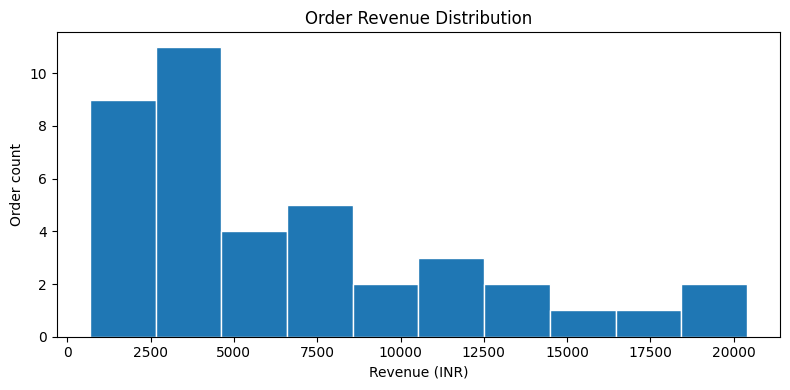

In [14]:
fig, ax=plt.subplots(figsize=(8,4))
ax.hist(df['Revenue'],bins=10,edgecolor='white')
ax.set(title='Order Revenue Distribution',xlabel='Revenue (INR)',ylabel='Order count')
fig.tight_layout(); fig.savefig('Day09_Revenue_Histogram.png',dpi=150); plt.show()

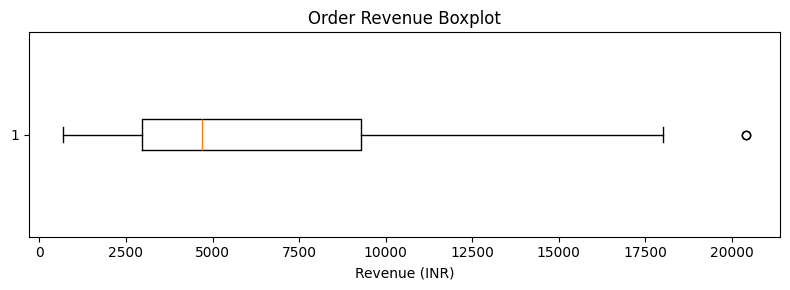

In [15]:
fig, ax=plt.subplots(figsize=(8,3))
ax.boxplot(df['Revenue'],vert=False)
ax.set(title='Order Revenue Boxplot',xlabel='Revenue (INR)')
fig.tight_layout();fig.savefig('Day09_Revenue_Boxplot.png',dpi=150);plt.show()

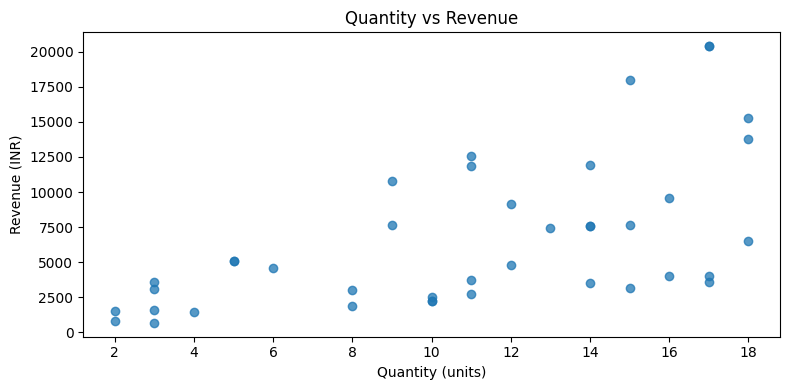

In [16]:
fig, ax=plt.subplots(figsize=(8,4))
ax.scatter(df['Quantity'],df['Revenue'],alpha=.75)
ax.set(title='Quantity vs Revenue',xlabel='Quantity (units)',ylabel='Revenue (INR)')
fig.tight_layout();fig.savefig('Day09_Quantity_Revenue_Scatter.png',dpi=150);plt.show()

## 5. Consolidated summary and business recommendations
**Interpretation cautions:** Revenue depends on quantity, price and discount. Correlation is not causation. Covariance units are units × INR. Sample variance and standard deviation use n−1; population formulas use n. Outliers must be reviewed before removal.

In [17]:
summary = pd.DataFrame({'Statistic':['Mean','Median','Mode(s)','Range','Sample variance','Sample standard deviation','10th percentile','25th percentile / Q1','50th percentile / Q2','75th percentile / Q3','90th percentile','IQR','Pearson correlation: Quantity/Revenue','Sample covariance: Quantity/Revenue'], 'Value':[df.Revenue.mean(),df.Revenue.median(),str(df.Revenue.mode().tolist()),df.Revenue.max()-df.Revenue.min(),df.Revenue.var(ddof=1),df.Revenue.std(ddof=1),df.Revenue.quantile(.1),df.Revenue.quantile(.25),df.Revenue.quantile(.5),df.Revenue.quantile(.75),df.Revenue.quantile(.9),iqr,df.Quantity.corr(df.Revenue),df.Quantity.cov(df.Revenue)]})
print(summary.to_string(index=False))
summary.to_csv('Day09_Statistics_Summary.csv',index=False)

                            Statistic                                     Value
                                 Mean                                 6679.0625
                               Median                                    4695.0
                              Mode(s) [2250.0, 5100.0, 7560.0, 7650.0, 20400.0]
                                Range                                   19725.0
                      Sample variance                           28258246.374199
            Sample standard deviation                               5315.848603
                      10th percentile                                    1611.0
                 25th percentile / Q1                                    2967.5
                 50th percentile / Q2                                    4695.0
                 75th percentile / Q3                                    9285.0
                      90th percentile                                   13923.0
                                  IQR   

## 6. Internship evidence checklist
- Screenshot: dataset loading and first five rows.
- Screenshot: mean through IQR outputs.
- Screenshot: correlation and covariance.
- Screenshot: histogram, boxplot and scatter plot.
- Screenshot: final consolidated summary.

**Conclusion:** Descriptive statistics explain typical order value, variation, percentiles, outlier candidates and associations, supporting pricing, inventory and sales analysis.